<a href="https://colab.research.google.com/github/andres-merino/FormatoBaseProyectos/blob/main/Plantilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Carrera de Ciencia de Datos</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Asignatura &bull; Tema
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; 2025-01
            </font></p>
        </td>  
    </tr>
</table>

# Reto No. 1: Aprendizaje No Supervisado - Perfilamiento de Futbolistas
**Equipo:** Grupo I

**Pregunta esencial:** ¿Qué perfiles futbolísticos aparecen en la base de datos según el volumen de participación, el rendimiento goleador y creador, la precisión en pases y la disciplina?

**Alcance:** Análisis exploratorio de estadísticas históricas de futbolistas mediante algoritmos de agrupamiento no supervisado. Los clústeres describen perfiles similares y no constituyen un ranking de desempeño.

**Técnicas utilizadas:**
Se aplicarán K-Means y Agrupamiento Jerárquico para formar los clústeres, evaluando la calidad con el coeficiente de silueta. Posteriormente, se utilizará Análisis de Componentes Principales (PCA) estrictamente para la visualización en 2D.

Los paquetes necesarios son:

In [1]:
# Paquetes necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

---
## <font color='264CC7'> Lectura de datos </font>


Auditoría inicial de la base de datos:
Dimensiones (filas, columnas): (233, 42)

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 233 entries, 0 to 232
Data columns (total 42 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ranking_influencia         233 non-null    int64  
 1   jugador                    233 non-null    str    
 2   nacionalidad               233 non-null    str    
 3   confederacion              233 non-null    str    
 4   posicion_principal         233 non-null    str    
 5   posicion_base              233 non-null    str    
 6   rol_campo                  233 non-null    str    
 7   periodo_activo_siglo_xxi   233 non-null    str    
 8   clubes_emblematicos        233 non-null    str    
 9   legado_e_influencia        233 non-null    str    
 10  anio_inicio                233 non-null    int64  
 11  anio_fin                   233 non-null    int64  
 12  anios_activos  

,partidos_jugados,titulos_colectivos,precision_pases_pct,goles_por_90,asistencias_por_90,tarjetas_amarillas_por_90
count,233.000000,233.000000,233.000000,233.000000,233.000000,233.000000
mean,638.630901,16.103004,84.063948,0.248841,0.166227,0.125811
std,200.264914,9.038597,4.658528,0.210266,0.101692,0.055152
min,164.000000,0.000000,72.200000,0.000000,0.001000,0.021000
25%,512.000000,9.000000,80.600000,0.075000,0.088000,0.089000
50%,642.000000,15.000000,84.600000,0.192000,0.162000,0.120000
75%,765.000000,21.000000,88.000000,0.416000,0.238000,0.163000
max,1343.000000,49.000000,93.500000,0.943000,0.417000,0.306000


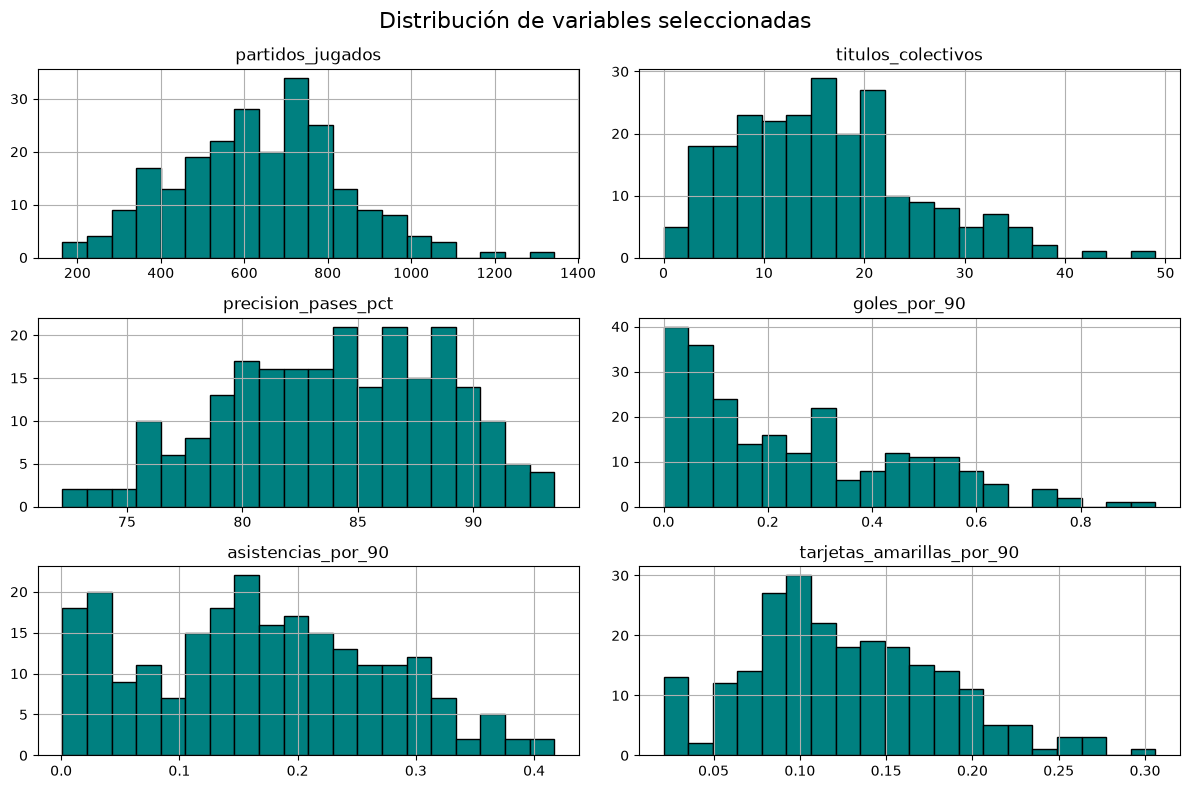

In [2]:

# Carga de datos cumpliendo las especificaciones del reto

url = 'https://raw.githubusercontent.com/juanfercaicedo/AprendizajeAutomaticoInicial/refs/heads/main/Dataset/futbollStats.csv'
try:
    df = pd.read_csv(url)
except Exception:
    import ssl
    from urllib.request import urlopen

    with urlopen(url, context=ssl._create_unverified_context()) as response:
        df = pd.read_csv(response)

print("Auditoría inicial de la base de datos:")
print("Dimensiones (filas, columnas):", df.shape)
print("\nInformación general:")
df.info()

# Variables seleccionadas como punto de partida
features_cols = [
    'partidos_jugados',          # Volumen / longevidad
    'titulos_colectivos',        # Éxito competitivo
    'precision_pases_pct',       # Seguridad en la distribución
    'goles_por_90',              # Capacidad goleadora normalizada
    'asistencias_por_90',        # Creación de gol (evita duplicar con pases_clave_por_90, r=0.93)
    'tarjetas_amarillas_por_90', # Frecuencia disciplinaria (evita duplicar con rojas, r=0.75)
  ]
print("\nDescripción de variables seleccionadas:")
display(df[features_cols].describe())

# Representación gráfica de distribuciones
df[features_cols].hist(bins=20, figsize=(12, 8), color='teal', edgecolor='black')
plt.suptitle('Distribución de variables seleccionadas', fontsize=16)
plt.tight_layout()
plt.show()

**Auditoría y Selección:**
La unidad de observación son los jugadores. Se seleccionaron seis variables numéricas que representan distintas dimensiones del desempeño: partidos jugados, títulos colectivos, precisión de pase y producción goleadora, creadora y disciplinaria por 90 minutos.


## <font color='264CC7'> Procesamiento de Datos </font>


In [3]:
from sklearn.preprocessing import StandardScaler

# Copia de seguridad
df_clean = df.copy()


# Escalado de datos
X = df_clean[features_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Registros conservados para el clustering: {X_scaled.shape[0]}")

Registros conservados para el clustering: 233


## <font color='264CC7'> Análisis con Clustering </font>


--- Comparación de algoritmos ---
k=2 | Silueta K-Means: 0.2562 | Silueta Jerárquico: 0.2457
k=3 | Silueta K-Means: 0.2310 | Silueta Jerárquico: 0.1989
k=4 | Silueta K-Means: 0.2449 | Silueta Jerárquico: 0.2230
k=5 | Silueta K-Means: 0.2232 | Silueta Jerárquico: 0.2078
k=6 | Silueta K-Means: 0.2136 | Silueta Jerárquico: 0.1881


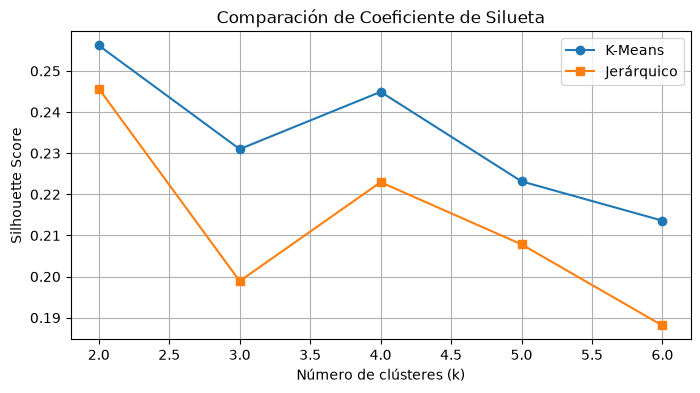


Número óptimo de clústeres: k=2 (Silueta=0.2562)

Tamaños de los grupos (K-Means):
Cluster
0    119
1    114
Name: count, dtype: int64


In [4]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

k_range = range(2, 7)
silhouette_km = []
silhouette_hc = []

print("--- Comparación de algoritmos ---")
for k in k_range:
    # K-Means con varias inicializaciones
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=15)
    labels_km = kmeans.fit_predict(X_scaled)
    sil_km = silhouette_score(X_scaled, labels_km)
    silhouette_km.append(sil_km)

    # Jerárquico (Ward, Euclidiana)
    hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels_hc = hc.fit_predict(X_scaled)
    sil_hc = silhouette_score(X_scaled, labels_hc)
    silhouette_hc.append(sil_hc)

    print(f"k={k} | Silueta K-Means: {sil_km:.4f} | Silueta Jerárquico: {sil_hc:.4f}")

# Gráfico comparativo
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_km, marker='o', label='K-Means')
plt.plot(k_range, silhouette_hc, marker='s', label='Jerárquico')
plt.title('Comparación de Coeficiente de Silueta')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True)
plt.show()

# Selección automática del mejor k según la silueta de K-Means
k_optimo = list(k_range)[int(np.argmax(silhouette_km))]
print(f"\nNúmero óptimo de clústeres: k={k_optimo} (Silueta={max(silhouette_km):.4f})")
modelo_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=15)
df_clean['Cluster'] = modelo_final.fit_predict(X_scaled)

print("\nTamaños de los grupos (K-Means):")
print(df_clean['Cluster'].value_counts())

## <font color='264CC7'> Reducción de Dimensiones </font>


Varianza explicada individual: [0.33316418 0.26668063]
Varianza explicada acumulada: 0.5998


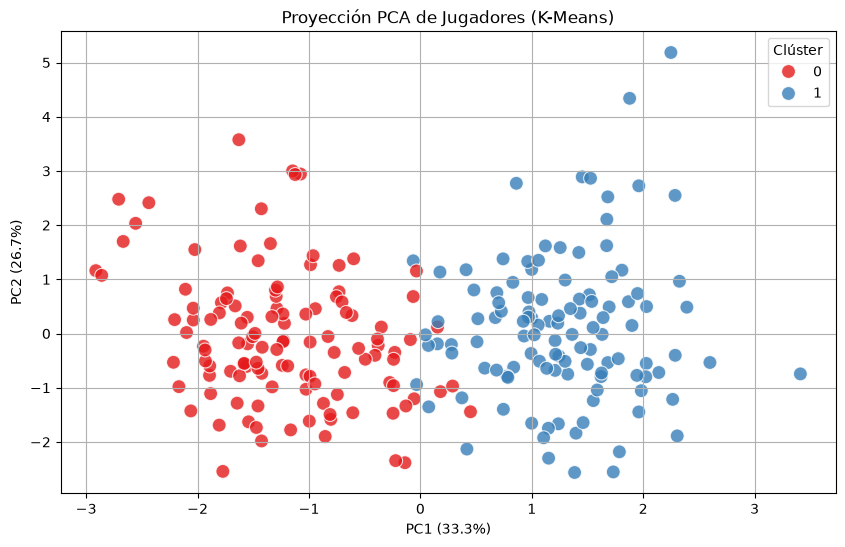


Contribución de variables a las componentes:


,partidos_jugados,titulos_colectivos,precision_pases_pct,goles_por_90,asistencias_por_90,tarjetas_amarillas_por_90
PC1,0.022889,-0.175280,-0.563724,0.617901,0.428641,-0.292292
PC2,0.683554,0.676473,0.093678,0.143373,0.202961,0.067924


In [5]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianza explicada individual: {pca.explained_variance_ratio_}")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.sum():.4f}")

# Visualización
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_clean['Cluster'], palette='Set1', s=100, alpha=0.8)
plt.title('Proyección PCA de Jugadores (K-Means)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(title='Clúster')
plt.grid(True)
plt.show()

# Contribuciones
contribuciones = pd.DataFrame(pca.components_, columns=features_cols, index=['PC1', 'PC2'])
print("\nContribución de variables a las componentes:")
display(contribuciones)